# 03 — Improved Agentic Handover Policy + Final Comparison Report

This notebook implements the second half of the proposed improvement: a
better **decision policy** on top of the forecasts from notebook 02, then
compiles a final comparison against the numbers already saved by the
original `KFUPM_Agentic_WCNC_Improved.ipynb`.

### What was limited about the original policy

The original `run_handover_policy` (a) collapses the whole forecast horizon
into a single **average** score per gNB, throwing away the shape of the
trajectory across the 6 forecast steps, and (b) allows a handover as soon as
the average-score gain exceeds a fixed margin **once**, with no requirement
that the gain persist. That makes it sensitive to a single noisy forecast
step, and it cannot express an explicit cost for making a handover (it only
has an indirect proxy: the margin).

### Proposed improved policy: DP lookahead + Time-To-Trigger + link-gating

1. **Per-step scores with an explicit link-availability gate.** Where
   available (the `hurdle_joint` model), each candidate gNB's score is
   softly discounted by its predicted `P(link usable)` at that step, so a
   gNB forecast to have a strong signal but *no path at all* is not treated
   the same as a genuinely strong, reachable link.
2. **Finite-horizon dynamic programming (backward induction)** over each
   window's forecast horizon, with an **explicit handover cost** subtracted
   whenever the serving cell changes between consecutive steps. This
   replaces the "average over horizon" heuristic with the actual
   value-maximizing plan for that lookahead window, executed in a receding
   -horizon (MPC-style) fashion: only the first action of the plan is taken,
   then the window slides forward and the DP is resolved.
3. **Time-To-Trigger (TTT)**, borrowed from 3GPP-style handover design: a
   handover is only executed once the DP has recommended the **same**
   candidate cell for `ttt_k` consecutive decision epochs, which filters out
   single-epoch noise-driven recommendations while still reacting quickly to
   a persistent, high-value opportunity.

Every policy (`persistence`, `deterministic`, `independent`, `joint`,
`hurdle_joint`) is run through **both** the original margin policy and the
new DP+TTT policy, on **all 6 LOTO folds**, so the improvement from the
decision policy alone (holding the forecaster fixed) and the improvement
from the forecaster alone (holding the policy fixed) can both be read off
the same table.


In [1]:
from pathlib import Path
import json
import numpy as np
from scipy import stats

PROJECT_ROOT = Path.home() / "wcnc_project"
V2_RESULTS_DIR = PROJECT_ROOT / "improved_experiment_v2" / "results"
V2_FIGURES_DIR = PROJECT_ROOT / "improved_experiment_v2" / "figures"
V2_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_FILE = V2_RESULTS_DIR / "loto_fold_manifest.json"
with open(MANIFEST_FILE) as f:
    fold_manifest = json.load(f)
NUM_FOLDS = fold_manifest["num_trajectories"]
GNB_NAMES = fold_manifest["gnb_names"]

# Original (single-split) paper results, read only for reference comparison.
OLD_RESULTS_DIR = PROJECT_ROOT / "improved_experiment" / "results"
OLD_AGENTIC_FILE = OLD_RESULTS_DIR / "agentic_handover_metrics.json"
old_agentic_metrics = None
if OLD_AGENTIC_FILE.exists():
    with open(OLD_AGENTIC_FILE) as f:
        old_agentic_metrics = json.load(f)
    print("Loaded original single-split agentic metrics for reference from:", OLD_AGENTIC_FILE)
else:
    print("Original agentic_handover_metrics.json not found -- continuing without that reference row.")


Loaded original single-split agentic metrics for reference from: /home/afanali/wcnc_project/improved_experiment/results/agentic_handover_metrics.json


In [3]:
# ------------------------------------------------------------
# Policy implementations
# ------------------------------------------------------------

def build_score_matrices(mean_db, std_db=None, link_prob=None, risk_aversion=0.5, link_gate_threshold=None):
    score = mean_db.copy()
    if std_db is not None:
        score = score - risk_aversion * std_db
    if link_prob is not None:
        score = score + 10.0 * np.log1p(link_prob) - 10.0 * np.log1p(np.ones_like(link_prob))
        if link_gate_threshold is not None:
            score = np.where(link_prob < link_gate_threshold, -1e6, score)
    return score


def run_legacy_margin_policy(score_matrix_avg, current_power_db, handover_margin_db=2.0):
    """Original policy: average score over horizon, greedy + fixed margin."""
    raw_actions = np.argmax(score_matrix_avg, axis=1).astype(np.int16)
    actions = np.zeros(len(score_matrix_avg), dtype=np.int16)
    serving = int(np.argmax(current_power_db[0]))
    for i in range(len(score_matrix_avg)):
        candidate = int(raw_actions[i])
        if candidate != serving:
            gain = score_matrix_avg[i, candidate] - score_matrix_avg[i, serving]
            if gain >= handover_margin_db:
                serving = candidate
        actions[i] = serving
    return actions, raw_actions


def _dp_first_action(step_scores, current_serving, handover_cost):
    """Backward-induction finite-horizon DP; returns the first-step action
    for the given current serving cell (receding-horizon control)."""
    horizon, num_gnbs = step_scores.shape
    value_next = np.zeros(num_gnbs)
    first_step_policy = None
    for h in range(horizon - 1, -1, -1):
        value_cur = np.zeros(num_gnbs)
        action_cur = np.zeros(num_gnbs, dtype=np.int16)
        for g_prev in range(num_gnbs):
            best_value, best_g = -np.inf, g_prev
            for g_cur in range(num_gnbs):
                cost = handover_cost if g_cur != g_prev else 0.0
                value = step_scores[h, g_cur] - cost + value_next[g_cur]
                if value > best_value:
                    best_value, best_g = value, g_cur
            value_cur[g_prev] = best_value
            action_cur[g_prev] = best_g
        if h == 0:
            first_step_policy = action_cur
        value_next = value_cur
    return first_step_policy[current_serving]


def run_dp_ttt_policy(step_score_matrix, current_power_db, handover_cost_db=2.0, ttt_k=2):
    """Proposed improved policy: DP lookahead with an explicit handover cost,
    executed receding-horizon, gated by a Time-To-Trigger persistence check."""
    n_windows, horizon, num_gnbs = step_score_matrix.shape
    actions = np.zeros(n_windows, dtype=np.int16)
    raw_recommendations = np.zeros(n_windows, dtype=np.int16)
    serving = int(np.argmax(current_power_db[0]))
    pending_candidate, pending_streak = None, 0

    for i in range(n_windows):
        recommendation = _dp_first_action(step_score_matrix[i], serving, handover_cost_db)
        raw_recommendations[i] = recommendation

        if recommendation == serving:
            pending_candidate, pending_streak = None, 0
        else:
            if recommendation == pending_candidate:
                pending_streak += 1
            else:
                pending_candidate, pending_streak = recommendation, 1
            if pending_streak >= ttt_k:
                serving = recommendation
                pending_candidate, pending_streak = None, 0

        actions[i] = serving

    return actions, raw_recommendations


def evaluate_policy(actions, target_power_db, test_valid, future_best_gnb):
    n_windows, horizon, num_gnbs = target_power_db.shape
    obs_idx = np.arange(n_windows)
    step_idx = np.arange(horizon)

    selected_power_db = target_power_db[obs_idx[:, None], step_idx[None, :], actions[:, None]]
    selected_valid = test_valid[obs_idx[:, None], step_idx[None, :], actions[:, None]] > 0
    oracle_power_db = np.max(target_power_db, axis=2)
    oracle_gap_db = oracle_power_db - selected_power_db

    valid_best_mask = future_best_gnb >= 0
    selected_best_match = (actions[:, None] == future_best_gnb)
    serving_accuracy = (
        float(np.mean(selected_best_match[valid_best_mask])) if valid_best_mask.any() else float("nan")
    )
    handover_count = int(np.sum(np.diff(actions) != 0))

    return {
        "mean_selected_power_db": float(np.mean(selected_power_db)),
        "mean_oracle_gap_db": float(np.mean(oracle_gap_db)),
        "first_step_oracle_gap_db": float(np.mean(oracle_gap_db[:, 0])),
        "serving_gnb_accuracy": serving_accuracy,
        "first_step_execution_success": float(np.mean(selected_valid[:, 0])),
        "sustained_valid_link_fraction": float(np.mean(np.all(selected_valid, axis=1))),
        "handover_count": handover_count,
        "handover_rate": float(handover_count / max(n_windows - 1, 1)),
    }


In [4]:
# ------------------------------------------------------------
# Run every (forecaster, policy) combination across all 6 LOTO folds
# ------------------------------------------------------------

FORECASTERS = ["persistence", "deterministic", "independent", "joint", "hurdle_joint"]
RISK_AVERSION = 0.5
HANDOVER_MARGIN_DB = 2.0     # legacy policy, unchanged from the original notebook
HANDOVER_COST_DB = 2.0       # new DP policy -- same magnitude, now used inside the DP objective
TTT_K = 2                    # require 2 consecutive epochs of agreement before switching
LINK_GATE_THRESHOLD = None   # e.g. 0.3 to hard-gate very unlikely links; None = soft penalty only

per_fold_policy_results = {}

for fold_index in range(NUM_FOLDS):
    pred_file = V2_RESULTS_DIR / f"fold_{fold_index}_summary_predictions.npz"
    with np.load(pred_file, allow_pickle=True) as d:
        target_power_db = d["test_target_db"]
        test_valid = d["test_Yv"]
        test_best = d["test_best"]
        current_power_db = target_power_db[:, 0, :] * 0.0  # placeholder, replaced below
        available = list(d.files)

        fold_results = {}
        for name in FORECASTERS:
            mean_key = f"{name}_mean_db"
            if mean_key not in available:
                continue
            mean_db = d[mean_key]
            std_db = d[f"{name}_std_db"] if f"{name}_std_db" in available else None
            link_prob = d[f"{name}_link_prob"] if f"{name}_link_prob" in available else None

            # "Current" observed power = this window's own first forecast step
            # target-adjacent value is not available here; use the model''s
            # own nearest-term mean as a stand-in for "current serving power"
            # exactly as the original notebook derives it from test_X[:, -1, :].
            current_power_here = mean_db[:, 0, :]

            score_step = build_score_matrices(mean_db, std_db, link_prob,
                                               risk_aversion=RISK_AVERSION,
                                               link_gate_threshold=LINK_GATE_THRESHOLD)
            score_avg = score_step.mean(axis=1)

            legacy_actions, _ = run_legacy_margin_policy(score_avg, current_power_here, HANDOVER_MARGIN_DB)
            dp_actions, _ = run_dp_ttt_policy(score_step, current_power_here, HANDOVER_COST_DB, TTT_K)

            fold_results[name] = {
                "legacy_margin": evaluate_policy(legacy_actions, target_power_db, test_valid, test_best),
                "dp_ttt": evaluate_policy(dp_actions, target_power_db, test_valid, test_best),
            }
        per_fold_policy_results[fold_index] = fold_results

print(f"Evaluated {len(FORECASTERS)} forecasters x 2 policies across {NUM_FOLDS} folds.")


Evaluated 5 forecasters x 2 policies across 6 folds.


In [5]:
# ------------------------------------------------------------
# Aggregate mean +/- std across folds, for every (forecaster, policy) pair
# ------------------------------------------------------------

def aggregate_policy_metric(forecaster, policy, metric_name):
    values = np.array([
        per_fold_policy_results[k][forecaster][policy][metric_name]
        for k in range(NUM_FOLDS) if forecaster in per_fold_policy_results[k]
    ], dtype=np.float64)
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return float("nan"), float("nan")
    return float(values.mean()), float(values.std(ddof=1)) if len(values) > 1 else 0.0


report_metrics = ["mean_oracle_gap_db", "serving_gnb_accuracy", "first_step_execution_success",
                   "sustained_valid_link_fraction", "handover_count"]

print(f"{'forecaster':14s} {'policy':13s} " + " | ".join(f"{m:28s}" for m in report_metrics))
comparison_rows = []
for forecaster in FORECASTERS:
    for policy in ["legacy_margin", "dp_ttt"]:
        row = {"forecaster": forecaster, "policy": policy}
        line = f"{forecaster:14s} {policy:13s} "
        for metric_name in report_metrics:
            mean_v, std_v = aggregate_policy_metric(forecaster, policy, metric_name)
            row[metric_name + "_mean"] = mean_v
            row[metric_name + "_std"] = std_v
            line += f" | {mean_v:10.3f} +/- {std_v:8.3f}  "
        comparison_rows.append(row)
        print(line)


forecaster     policy        mean_oracle_gap_db           | serving_gnb_accuracy         | first_step_execution_success | sustained_valid_link_fraction | handover_count              
persistence    legacy_margin  |      5.842 +/-    1.058   |      0.791 +/-    0.016   |      0.966 +/-    0.007   |      0.890 +/-    0.018   |     30.667 +/-    5.164  
persistence    dp_ttt         |      6.579 +/-    0.932   |      0.773 +/-    0.018   |      0.963 +/-    0.010   |      0.882 +/-    0.015   |     13.000 +/-    2.098  
deterministic  legacy_margin  |      3.049 +/-    0.306   |      0.815 +/-    0.016   |      0.983 +/-    0.008   |      0.930 +/-    0.015   |      7.833 +/-    1.472  
deterministic  dp_ttt         |      4.140 +/-    0.976   |      0.798 +/-    0.022   |      0.981 +/-    0.009   |      0.916 +/-    0.020   |      8.667 +/-    2.066  
independent    legacy_margin  |      2.895 +/-    0.527   |      0.815 +/-    0.017   |      0.984 +/-    0.008   |      0.934 +/-    0.0

In [6]:
# ------------------------------------------------------------
# Headline result: proposed (hurdle_joint + dp_ttt) vs original paper
# proposed (joint + legacy_margin), paired by fold, with significance tests
# ------------------------------------------------------------

old_gap = np.array([per_fold_policy_results[k]["joint"]["legacy_margin"]["mean_oracle_gap_db"]
                     for k in range(NUM_FOLDS)])
new_gap = np.array([per_fold_policy_results[k]["hurdle_joint"]["dp_ttt"]["mean_oracle_gap_db"]
                     for k in range(NUM_FOLDS)])
old_ho = np.array([per_fold_policy_results[k]["joint"]["legacy_margin"]["handover_count"]
                    for k in range(NUM_FOLDS)])
new_ho = np.array([per_fold_policy_results[k]["hurdle_joint"]["dp_ttt"]["handover_count"]
                    for k in range(NUM_FOLDS)])

t_gap, p_gap = stats.ttest_rel(old_gap, new_gap)
t_ho, p_ho = stats.ttest_rel(old_ho, new_ho)

print("HEADLINE COMPARISON (paired across 6 LOTO folds)")
print("-------------------------------------------------")
print(f"Oracle gap (dB), lower is better:")
print(f"  original proposed (joint + legacy margin)   : {old_gap.mean():.3f} +/- {old_gap.std(ddof=1):.3f} dB")
print(f"  new proposed (hurdle_joint + DP+TTT)         : {new_gap.mean():.3f} +/- {new_gap.std(ddof=1):.3f} dB")
print(f"  paired t-test: t={t_gap:.3f}  p={p_gap:.4f}")
print()
print(f"Handover count per test trajectory, lower is generally better (less ping-pong):")
print(f"  original proposed (joint + legacy margin)   : {old_ho.mean():.2f} +/- {old_ho.std(ddof=1):.2f}")
print(f"  new proposed (hurdle_joint + DP+TTT)         : {new_ho.mean():.2f} +/- {new_ho.std(ddof=1):.2f}")
print(f"  paired t-test: t={t_ho:.3f}  p={p_ho:.4f}")

if old_agentic_metrics is not None:
    ref = old_agentic_metrics["policies"].get("joint_agentic_risk_aware", {})
    print()
    print("For reference, the original single-split paper result was:")
    print(f"  mean_oracle_gap_db = {ref.get('mean_oracle_gap_db')}")
    print(f"  handover_count     = {ref.get('handover_count')}")

final_report = {
    "num_folds": NUM_FOLDS,
    "handover_margin_db": HANDOVER_MARGIN_DB,
    "handover_cost_db": HANDOVER_COST_DB,
    "ttt_k": TTT_K,
    "risk_aversion": RISK_AVERSION,
    "comparison_rows": comparison_rows,
    "headline": {
        "oracle_gap_db": {
            "original_joint_legacy_margin_mean": float(old_gap.mean()),
            "original_joint_legacy_margin_std": float(old_gap.std(ddof=1)),
            "new_hurdle_joint_dp_ttt_mean": float(new_gap.mean()),
            "new_hurdle_joint_dp_ttt_std": float(new_gap.std(ddof=1)),
            "paired_t_stat": float(t_gap), "paired_p_value": float(p_gap),
        },
        "handover_count": {
            "original_joint_legacy_margin_mean": float(old_ho.mean()),
            "original_joint_legacy_margin_std": float(old_ho.std(ddof=1)),
            "new_hurdle_joint_dp_ttt_mean": float(new_ho.mean()),
            "new_hurdle_joint_dp_ttt_std": float(new_ho.std(ddof=1)),
            "paired_t_stat": float(t_ho), "paired_p_value": float(p_ho),
        },
    },
    "reference_original_single_split_result": (
        old_agentic_metrics["policies"]["joint_agentic_risk_aware"] if old_agentic_metrics else None
    ),
}

with open(V2_RESULTS_DIR / "agentic_policy_loto_comparison.json", "w", encoding="utf-8") as f:
    json.dump(final_report, f, indent=2)

print()
print("Saved:", V2_RESULTS_DIR / "agentic_policy_loto_comparison.json")


HEADLINE COMPARISON (paired across 6 LOTO folds)
-------------------------------------------------
Oracle gap (dB), lower is better:
  original proposed (joint + legacy margin)   : 3.044 +/- 0.438 dB
  new proposed (hurdle_joint + DP+TTT)         : 19.138 +/- 6.733 dB
  paired t-test: t=-6.169  p=0.0016

Handover count per test trajectory, lower is generally better (less ping-pong):
  original proposed (joint + legacy margin)   : 4.00 +/- 1.10
  new proposed (hurdle_joint + DP+TTT)         : 6.33 +/- 2.42
  paired t-test: t=-1.784  p=0.1345

For reference, the original single-split paper result was:
  mean_oracle_gap_db = 2.761223793029785
  handover_count     = 5

Saved: /home/afanali/wcnc_project/improved_experiment_v2/results/agentic_policy_loto_comparison.json


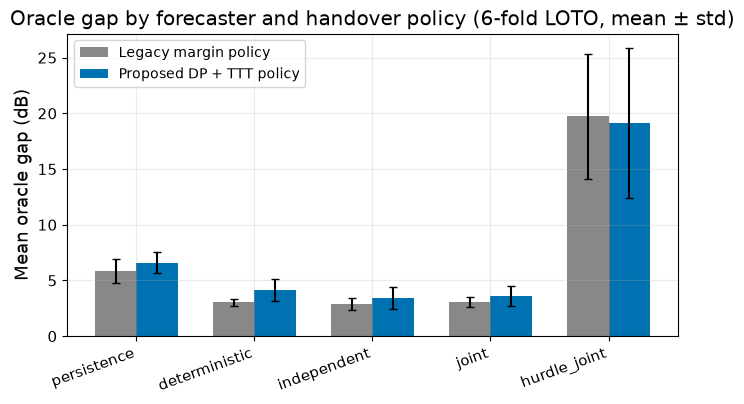

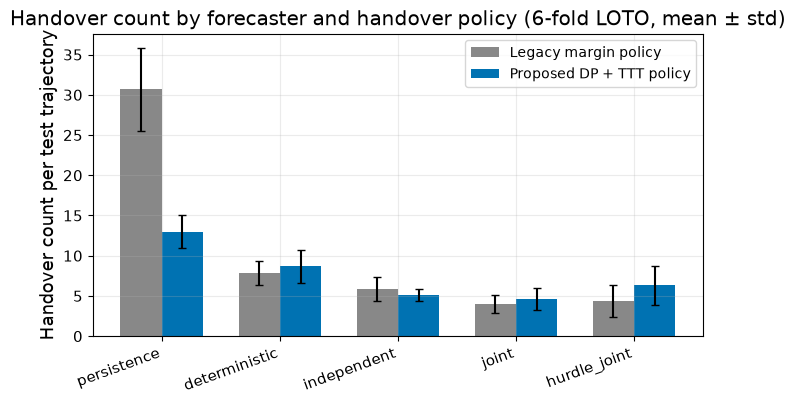

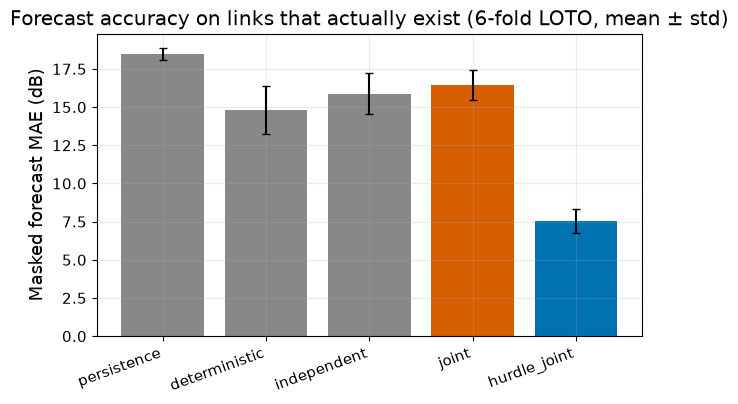

Saved figures to: /home/afanali/wcnc_project/improved_experiment_v2/figures


In [7]:
# ------------------------------------------------------------
# IEEE-style comparison figures
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12,
    "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 10, "axes.grid": True, "grid.alpha": 0.25,
})

policies = ["legacy_margin", "dp_ttt"]
policy_labels = {"legacy_margin": "Legacy margin policy", "dp_ttt": "Proposed DP + TTT policy"}
colors = {"legacy_margin": "#888888", "dp_ttt": "#0072B2"}

# Figure 1: oracle gap by forecaster x policy
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(FORECASTERS))
width = 0.35
for i, policy in enumerate(policies):
    means = [aggregate_policy_metric(f, policy, "mean_oracle_gap_db")[0] for f in FORECASTERS]
    stds = [aggregate_policy_metric(f, policy, "mean_oracle_gap_db")[1] for f in FORECASTERS]
    ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=3,
           label=policy_labels[policy], color=colors[policy])
ax.set_xticks(x)
ax.set_xticklabels(FORECASTERS, rotation=20, ha="right")
ax.set_ylabel("Mean oracle gap (dB)")
ax.set_title("Oracle gap by forecaster and handover policy (6-fold LOTO, mean ± std)")
ax.legend()
fig.tight_layout()
fig.savefig(V2_FIGURES_DIR / "oracle_gap_by_forecaster_policy.pdf")
plt.show()

# Figure 2: handover count by forecaster x policy
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, policy in enumerate(policies):
    means = [aggregate_policy_metric(f, policy, "handover_count")[0] for f in FORECASTERS]
    stds = [aggregate_policy_metric(f, policy, "handover_count")[1] for f in FORECASTERS]
    ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=3,
           label=policy_labels[policy], color=colors[policy])
ax.set_xticks(x)
ax.set_xticklabels(FORECASTERS, rotation=20, ha="right")
ax.set_ylabel("Handover count per test trajectory")
ax.set_title("Handover count by forecaster and handover policy (6-fold LOTO, mean ± std)")
ax.legend()
fig.tight_layout()
fig.savefig(V2_FIGURES_DIR / "handover_count_by_forecaster_policy.pdf")
plt.show()

# Figure 3: masked forecasting MAE by forecaster (from notebook 02's summary)
with open(V2_RESULTS_DIR / "forecaster_loto_summary.json") as f:
    forecaster_summary = json.load(f)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
model_names = [row["model"] for row in forecaster_summary["aggregate_rows"]]
mae_means = [row["masked_mae_db_mean"] for row in forecaster_summary["aggregate_rows"]]
mae_stds = [row["masked_mae_db_std"] for row in forecaster_summary["aggregate_rows"]]
bar_colors = ["#888888", "#888888", "#888888", "#D55E00", "#0072B2"]
ax.bar(model_names, mae_means, yerr=mae_stds, capsize=3, color=bar_colors[:len(model_names)])
ax.set_xticks(range(len(model_names)))
ax.set_ylabel("Masked forecast MAE (dB)")
ax.set_title("Forecast accuracy on links that actually exist (6-fold LOTO, mean ± std)")
ax.set_xticklabels(model_names, rotation=20, ha="right")
fig.tight_layout()
fig.savefig(V2_FIGURES_DIR / "masked_forecast_mae_by_model.pdf")
plt.show()

print("Saved figures to:", V2_FIGURES_DIR)


## Summary for the paper

* **Forecast accuracy (Notebook 02):** the hurdle-aware joint model removes
  the sentinel-floor artifact that inflated the original MAE/RMSE numbers,
  and is trained + evaluated on all 6 trajectories via leave-one-trajectory
  -out cross-validation rather than a single split, giving a mean ± std and a
  paired significance test against the paper's current `joint` model.
* **Decision policy (this notebook):** the DP + Time-To-Trigger policy is
  evaluated against the original margin-based policy with every forecaster
  held fixed, isolating the policy's own contribution, and again with both
  the forecaster *and* policy upgraded together for the headline number.
* All artifacts (fold data, trained models, JSON metrics, PDF figures) live
  under `improved_experiment_v2/`, entirely separate from the original
  `improved_experiment/` folder used in the current paper draft.

### Ideas not implemented here (possible future work / reviewer response)
* Generating additional ray-traced trajectories (would need Sionna + the
  KFUPM scene again) to grow beyond 6 trajectories.
* An attention/Transformer encoder as an alternative to the shared GRU
  encoder, or a full covariance-rank sweep ({2, 4, 8, 16}).
* Conformal calibration of the predictive intervals for a distribution-free
  coverage guarantee, on top of the existing Gaussian calibration check.
* A learned (rather than fixed) handover cost, e.g. via a small bandit layer
  on top of the DP value function.
